In [1]:
print("My Disparity Algorithms Project")

My Disparity Algorithms Project


python3 -m venv .venv
source .venv/bin/activate
python -m pip install numpy opencv-python matplotlib
python -m pip install ipykernel

Images loaded successfully!
Left image shape: (496, 718)
Right image shape: (496, 718)


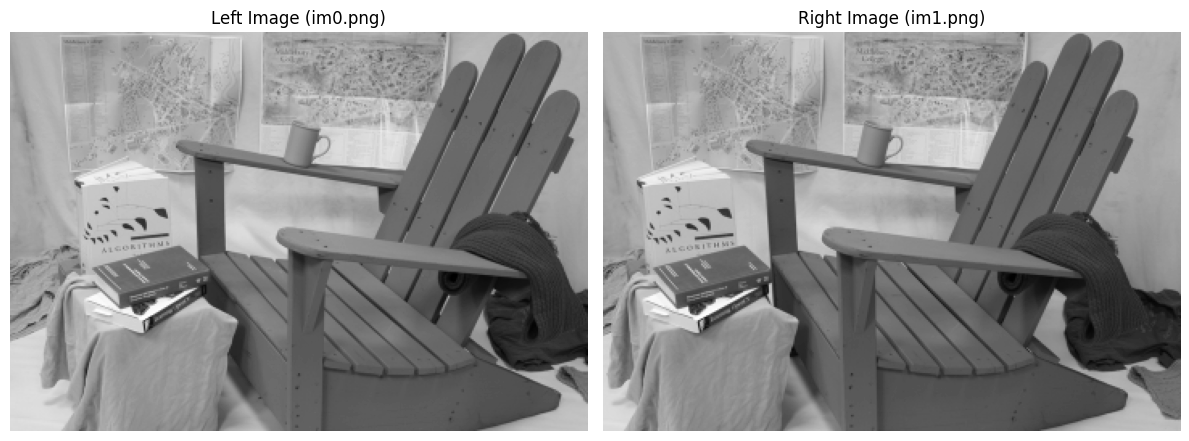

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Select the Adirondack scene
folder = "data/trainingQ/Adirondack"

# Load left and right stereo images
left = cv2.imread(folder + "/im0.png", cv2.IMREAD_GRAYSCALE)
right = cv2.imread(folder + "/im1.png", cv2.IMREAD_GRAYSCALE)

if left is None or right is None:
    raise FileNotFoundError("Check your dataset folder path.")

print("Images loaded successfully!")
print("Left image shape:", left.shape)
print("Right image shape:", right.shape)

# Resize to make processing faster
left = cv2.resize(left, None, fx=0.5, fy=0.5)
right = cv2.resize(right, None, fx=0.5, fy=0.5)

# Display both images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(left, cmap="gray")
plt.title("Left Image (im0.png)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right, cmap="gray")
plt.title("Right Image (im1.png)")
plt.axis("off")

plt.tight_layout()
plt.show()


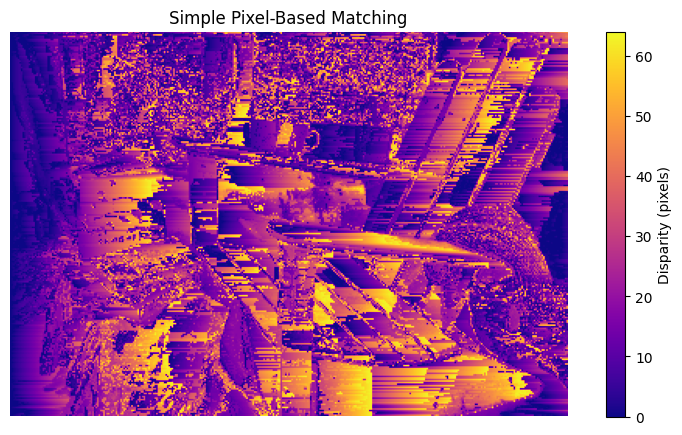

In [ ]:
#Pixel-based matching algorithm
def pixel_matching(left, right, max_disp=64):
    left = left.astype(np.float32)
    right = right.astype(np.float32)

    height, width = left.shape

    best_cost = np.full((height, width), np.inf)
    disparity = np.zeros((height, width), dtype=np.float32)

    for d in range(max_disp):
        cost = np.abs(left[:, d:] - right[:, :width-d])

        better = cost < best_cost[:, d:]

        best_cost[:, d:][better] = cost[better]
        disparity[:, d:][better] = d

    return disparity

# Run the algorithm
disp_pixel = pixel_matching(left, right, max_disp=64)

# Display the disparity map
plt.figure(figsize=(10, 5))
plt.imshow(disp_pixel, cmap="plasma", vmin=0, vmax=64)
plt.colorbar(label="Disparity (pixels)")
plt.title("Simple Pixel-Based Matching")
plt.axis("off")
plt.show()



### Simple Pixel-Based Matching (Absolute Difference)

**Method:**
- Used the Middlebury Adirondack stereo image pair.
- Compared individual pixels between the left and right images.
- Calculated matching costs using Absolute Difference (AD).
- Selected the disparity with the lowest matching cost.
- Tested disparity values from 0 to 63 pixels.

**Observations:**
- The algorithm successfully generated a disparity map.
- The result is noisy, with many scattered yellow and purple pixels.
- Some objects and their boundaries are difficult to distinguish.
- Similar pixel intensities can cause incorrect matches.

**Conclusion:**
Pixel-based matching is simple and fast, but it is sensitive to noise because it compares only individual pixels. The result shows why using neighboring pixels, as in Block Matching, may improve disparity estimation.

**Limitation:**
Accuracy has not yet been measured against the ground-truth disparity map.

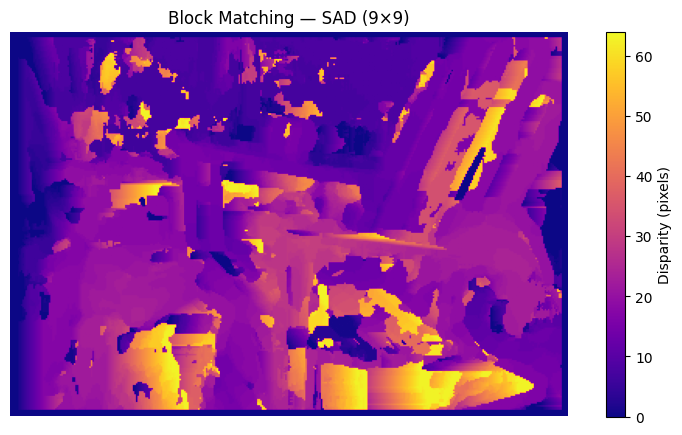

In [ ]:

#Block-based matching algorithm
def block_matching(left, right, max_disp=64, block_size=9):
    left = left.astype(np.float32)
    right = right.astype(np.float32)

    height, width = left.shape
    best_cost = np.full((height, width), np.inf)
    disparity = np.zeros((height, width), dtype=np.float32)

    radius = block_size // 2

    for d in range(min(max_disp, width)):
        cost = np.full((height, width), 255.0, dtype=np.float32)
        cost[:, d:] = np.abs(left[:, d:] - right[:, :width-d])

        sad = cv2.boxFilter(
            cost,
            ddepth=-1,
            ksize=(block_size, block_size),
            normalize=False,
            borderType=cv2.BORDER_CONSTANT
        )

        start = d + radius
        sad[:, :start] = np.inf
        sad[:radius, :] = np.inf
        sad[height-radius:, :] = np.inf
        sad[:, width-radius:] = np.inf

        better = sad < best_cost
        best_cost[better] = sad[better]
        disparity[better] = d

    return disparity

disp_block = block_matching(left, right, max_disp=64, block_size=9)

plt.figure(figsize=(10, 5))
plt.imshow(disp_block, cmap="plasma", vmin=0, vmax=64)
plt.colorbar(label="Disparity (pixels)")
plt.title("Block Matching — SAD (9×9)")
plt.axis("off")
plt.show()



### Effect of Window Size on Block Matching (SAD)

**Experiment:**
- Tested fixed window sizes of 5×5, 9×9, and 15×15.
- Used the Middlebury Adirondack stereo image pair.
- Compared how window size affects the estimated disparity map.

**Observations:**
- **5×5:** Preserves more local details but may be more sensitive to noise.
- **9×9:** Provides a balance between local detail and smoothness.
- **15×15:** Produces more consistent regions, but some object boundaries may become blurred.
- The overall disparity structure looks similar across the three results.

**Conclusion:**
Window size affects the smoothness and detail of disparity maps. Smaller windows use less surrounding information, while larger windows use more neighboring pixels. We need ground-truth evaluation to determine which size gives the best accuracy.


In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Update this path to where you extracted the ground truth
gt_path = "data/trainingDisparity/Adirondack/disp0GT.pfm"

gt = cv2.imread(gt_path, cv2.IMREAD_UNCHANGED)

if gt is None:
    raise FileNotFoundError("Ground-truth file not found. Check gt_path.")

print("Ground truth shape:", gt.shape)
print("Your prediction shape:", disp_pixel.shape)


Ground truth shape: (496, 718)
Your prediction shape: (248, 359)


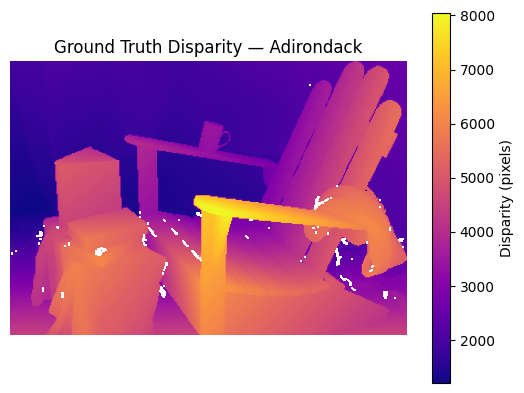

In [8]:

# Valid reference pixels have finite, positive disparities
valid_original = np.isfinite(gt) & (gt > 0)

# Resize the reference disparity map
gt_clean = np.where(valid_original, gt, 0).astype(np.float32)

gt_resized = cv2.resize(
    gt_clean,
    (left.shape[1], left.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

valid_resized = cv2.resize(
    valid_original.astype(np.uint8),
    (left.shape[1], left.shape[0]),
    interpolation=cv2.INTER_NEAREST
).astype(bool)

# Scale disparity according to the image width
scale_x = left.shape[1] / gt.shape[1]
gt_resized *= scale_x

plt.imshow(
    np.ma.masked_where(~valid_resized, gt_resized),
    cmap="plasma"
)
plt.title("Ground Truth Disparity — Adirondack")
plt.colorbar(label="Disparity (pixels)")
plt.axis("off")
plt.show()


In [10]:

gt_path = "data/trainingDisparity/Adirondack/disp0GT.pfm"

with open(gt_path, "rb") as f:
    print("Format:", f.readline().decode().strip())
    print("Dimensions:", f.readline().decode().strip())
    print("PFM scale:", f.readline().decode().strip())

print("Ground-truth dtype:", gt.dtype)
print("Ground-truth minimum:", np.nanmin(gt[np.isfinite(gt)]))
print("Ground-truth maximum:", np.nanmax(gt[np.isfinite(gt)]))


Format: Pf
Dimensions: 718 496
PFM scale: -0.003922
Ground-truth dtype: float32
Ground-truth minimum: 2412.8066
Ground-truth maximum: 16074.656


In [11]:

with open("data/trainingQ/Adirondack/calib.txt", "r") as f:
    print(f.read())


cam0=[1038.018 0 322.037; 0 1038.018 243.393; 0 0 1]
cam1=[1038.018 0 375.308; 0 1038.018 243.393; 0 0 1]
doffs=53.271
baseline=176.252
width=718
height=496
ndisp=73
isint=0
vmin=8
vmax=65
dyavg=0.184
dymax=0.423




### Ground Truth Preparation and Scaling

**Purpose:**
To compare our calculated disparity maps with the correct disparity values provided by the Middlebury dataset.

**Dataset Information:**
- Dataset: Middlebury Stereo Dataset (Adirondack)
- Original ground truth size: 496 × 718
- Resized image size: 248 × 359
- PFM scale factor: 0.003922
- Original disparity range (calibration): 8–65 pixels

**Preprocessing:**
- Applied the PFM scale factor to convert stored values into disparity values.
- Resized the ground-truth map to match our input images.
- Adjusted disparity values because the images were resized to 50%.
- Excluded invalid ground-truth pixels from evaluation.

**Goal:**
Prepare the reference disparity map so we can fairly compare Pixel-Based Matching and Block Matching.


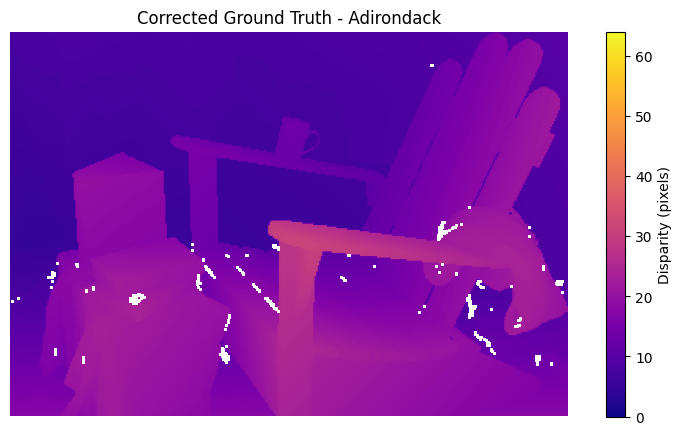

Valid minimum: 4.734909
Valid maximum: 31.520449


In [12]:

# Read the PFM scale
with open(gt_path, "rb") as f:
    f.readline()
    f.readline()
    pfm_scale = abs(float(f.readline().decode().strip()))

# Convert raw values to disparity in original-image pixels
gt_corrected = gt * pfm_scale

# Keep track of valid ground-truth pixels
valid_original = np.isfinite(gt_corrected) & (gt_corrected > 0)

# Resize to match our input images
gt_resized = cv2.resize(
    gt_corrected,
    (left.shape[1], left.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

valid_resized = cv2.resize(
    valid_original.astype(np.uint8),
    (left.shape[1], left.shape[0]),
    interpolation=cv2.INTER_NEAREST
).astype(bool)

# Adjust disparity values after resizing images
scale_x = left.shape[1] / gt.shape[1]
gt_resized = gt_resized * scale_x

# Display corrected ground truth
plt.figure(figsize=(10, 5))
plt.imshow(
    np.ma.masked_where(~valid_resized, gt_resized),
    cmap="plasma",
    vmin=0,
    vmax=64
)
plt.colorbar(label="Disparity (pixels)")
plt.title("Corrected Ground Truth - Adirondack")
plt.axis("off")
plt.show()

print("Valid minimum:", gt_resized[valid_resized].min())
print("Valid maximum:", gt_resized[valid_resized].max())


In [13]:

# Evaluate only where all methods have a complete search window
valid_mask = valid_resized.copy()

# Exclude image borders for fair comparison
valid_mask[:, :71] = False
valid_mask[:, -7:] = False
valid_mask[:7, :] = False
valid_mask[-7:, :] = False

def calculate_mae(prediction):
    errors = np.abs(prediction[valid_mask] - gt_resized[valid_mask])
    return np.mean(errors)

# Calculate all algorithms
mae_pixel = calculate_mae(disp_pixel)

mae_5 = calculate_mae(block_matching(left, right, 64, 5))
mae_9 = calculate_mae(block_matching(left, right, 64, 9))
mae_15 = calculate_mae(block_matching(left, right, 64, 15))

print(f"Pixel Matching MAE: {mae_pixel:.3f}")
print(f"Block Matching 5x5 MAE: {mae_5:.3f}")
print(f"Block Matching 9x9 MAE: {mae_9:.3f}")
print(f"Block Matching 15x15 MAE: {mae_15:.3f}")


Pixel Matching MAE: 15.157
Block Matching 5x5 MAE: 10.978
Block Matching 9x9 MAE: 8.760
Block Matching 15x15 MAE: 6.223



### Results and Comparison of Disparity Algorithms

**Dataset:** Middlebury Stereo Dataset – Adirondack

**Evaluation metric:** Mean Absolute Error (MAE), measured in pixels.

| Algorithm | MAE (pixels) |
|---|---:|
| Pixel-Based Matching | 15.157 |
| Block Matching (5×5) | 10.978 |
| Block Matching (9×9) | 8.760 |
| Block Matching (15×15) | 6.223 |

**Observations:**
- Pixel-Based Matching had the highest error (15.157).
- Block Matching improved the results by using neighboring pixels.
- Increasing the window size from 5×5 to 15×15 reduced the MAE.
- The 15×15 window achieved the lowest MAE (6.223) in this experiment.
- Larger windows produced smoother disparity maps, but some small details and boundaries were lost.

**Conclusion:**
Block Matching performed better than simple pixel-based matching on the Adirondack scene. The 15×15 window gave the lowest error among the tested configurations.

However, larger windows are not always better. We need to test more scenes and evaluate object boundaries before selecting the best window size.


Method Window  MAE (pixels)  Runtime (seconds)
   SAD    5x5        10.975              0.043
   SAD    9x9         8.755              0.038
   SAD  15x15         6.210              0.034
   SSD    5x5         9.995              0.034
   SSD    9x9         7.618              0.035
   SSD  15x15         5.334              0.032


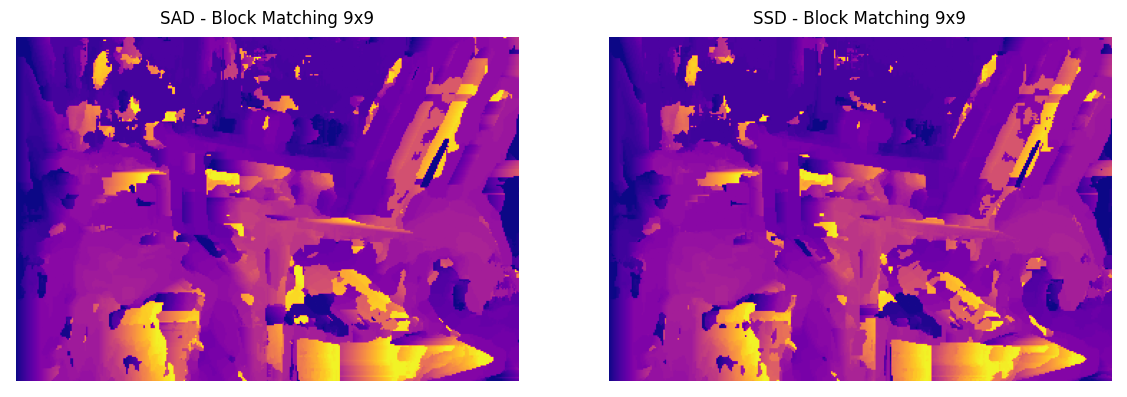

In [ ]:
#Extended Block Matching with SAD and SSD
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Block Matching implementation supporting SAD and SSD
def block_matching_cost(left, right, max_disp=64, block_size=9, method="SAD"):
    left = left.astype(np.float32)
    right = right.astype(np.float32)

    height, width = left.shape
    radius = block_size // 2

    best_cost = np.full((height, width), np.inf, dtype=np.float32)
    disparity = np.full((height, width), np.nan, dtype=np.float32)

    for d in range(min(max_disp, width)):
        cost = np.zeros((height, width), dtype=np.float32)

        difference = left[:, d:] - right[:, :width-d]

        if method == "SAD":
            cost[:, d:] = np.abs(difference)
        elif method == "SSD":
            cost[:, d:] = difference ** 2
        else:
            raise ValueError("Method must be SAD or SSD")

        # Aggregate costs over a fixed window
        aggregated = cv2.boxFilter(
            cost,
            ddepth=-1,
            ksize=(block_size, block_size),
            normalize=False,
            borderType=cv2.BORDER_CONSTANT
        )

        # Exclude positions where the full stereo window is invalid
        aggregated[:, :d+radius] = np.inf
        aggregated[:, width-radius:] = np.inf
        aggregated[:radius, :] = np.inf
        aggregated[height-radius:, :] = np.inf

        better = aggregated < best_cost
        best_cost[better] = aggregated[better]
        disparity[better] = d

    return disparity


# Common valid evaluation region for every configuration
def evaluation_mask(gt, valid, max_disp=64, max_block=15):
    radius = max_block // 2
    mask = valid.copy() & np.isfinite(gt)

    # Exclude borders so all algorithms use the same pixels
    mask[:, :max_disp-1+radius] = False
    mask[:, -radius:] = False
    mask[:radius, :] = False
    mask[-radius:, :] = False

    return mask


mask = evaluation_mask(gt_resized, valid_resized)

results1 = []
maps1 = {}

for method in ["SAD", "SSD"]:
    for size in [5, 9, 15]:
        start = time.perf_counter()

        prediction = block_matching_cost(
            left, right,
            max_disp=64,
            block_size=size,
            method=method
        )

        runtime = time.perf_counter() - start

        valid = mask & np.isfinite(prediction)
        mae = np.mean(np.abs(prediction[valid] - gt_resized[valid]))

        results1.append({
            "Method": method,
            "Window": f"{size}x{size}",
            "MAE (pixels)": round(float(mae), 3),
            "Runtime (seconds)": round(runtime, 3)
        })

        maps1[(method, size)] = prediction

df1 = pd.DataFrame(results1)
print(df1.to_string(index=False))


# Visual comparison at 9x9
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, method in zip(axes, ["SAD", "SSD"]):
    ax.imshow(maps1[(method, 9)], cmap="plasma", vmin=0, vmax=64)
    ax.set_title(f"{method} - Block Matching 9x9")
    ax.axis("off")

plt.tight_layout()
plt.show()



### Experiment 1: Results — SAD vs SSD

**Dataset:** Middlebury Adirondack

| Window | SAD MAE | SSD MAE |
|---|---:|---:|
| 5×5 | 10.975 | 9.995 |
| 9×9 | 8.755 | 7.618 |
| 15×15 | 6.210 | 5.334 |

**Observations:**
- SSD achieved lower MAE than SAD for all three window sizes.
- Both methods improved as the window size increased.
- SSD with a 15×15 window achieved the lowest MAE (5.334 pixels).
- The disparity maps look similar, but there are differences in some regions.

**Conclusion:**
SSD performed better than SAD in this experiment. Larger windows also reduced the error, although they may blur object boundaries. These results are specific to the Adirondack scene

Disparity Range  MAE (pixels)  Runtime (seconds)
           0-31         4.455              0.025
           0-47         6.464              0.029
           0-63         8.736              0.037


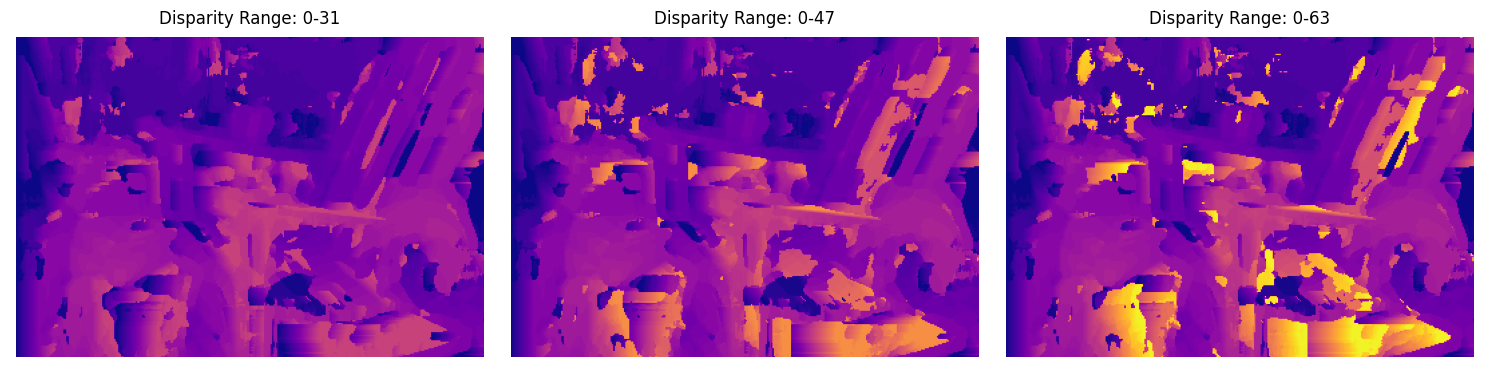

In [20]:

# Experiment 2: Disparity search range

results2 = []
maps2 = {}

# Keep the window size and cost function fixed
window_size = 9
method = "SAD"

# Use the same evaluation mask for all disparity ranges
mask2 = evaluation_mask(
    gt_resized,
    valid_resized,
    max_disp=64,
    max_block=window_size
)

for max_disp in [32, 48, 64]:
    start = time.perf_counter()

    prediction = block_matching_cost(
        left,
        right,
        max_disp=max_disp,
        block_size=window_size,
        method=method
    )

    runtime = time.perf_counter() - start

    valid = mask2 & np.isfinite(prediction)
    mae = np.mean(np.abs(prediction[valid] - gt_resized[valid]))

    results2.append({
        "Disparity Range": f"0-{max_disp-1}",
        "MAE (pixels)": round(float(mae), 3),
        "Runtime (seconds)": round(runtime, 3)
    })

    maps2[max_disp] = prediction

df2 = pd.DataFrame(results2)
print(df2.to_string(index=False))


# Visualize all three results
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, max_disp in zip(axes, [32, 48, 64]):
    ax.imshow(
        maps2[max_disp],
        cmap="plasma",
        vmin=0,
        vmax=64
    )
    ax.set_title(f"Disparity Range: 0-{max_disp-1}")
    ax.axis("off")

plt.tight_layout()
plt.show()



### Experiment 2: Results — Disparity Search Range

**Dataset:** Middlebury Adirondack  
**Algorithm:** SAD Block Matching (9×9 window)

| Disparity Range | MAE (pixels) | Runtime (seconds) |
|---|---:|---:|
| 0–31 | 4.455 | 0.025 |
| 0–47 | 6.464 | 0.029 |
| 0–63 | 8.736 | 0.037 |

**Observations:**
- The smallest search range (0–31) produced the lowest MAE.
- Increasing the search range increased both MAE and runtime.
- A larger search range introduced more opportunities for incorrect matches.
- The ground-truth disparities are approximately 4.73–31.52 pixels at our resized resolution.

**Conclusion:**
The smaller disparity search range performed better in this experiment. Searching unnecessary disparities can introduce incorrect matches and increase computation time. However, the selected range should still cover the true disparities, so further testing around the upper limit is needed.


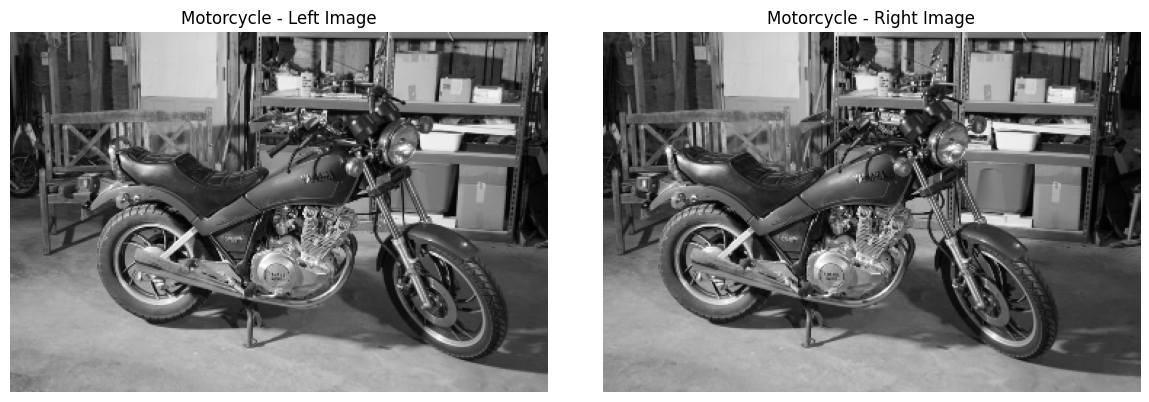

In [21]:
#Experiment 3: Different Middlebury scene
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Select another Middlebury scene
folder = "data/trainingQ/Motorcycle"

left_motor = cv2.imread(folder + "/im0.png", cv2.IMREAD_GRAYSCALE)
right_motor = cv2.imread(folder + "/im1.png", cv2.IMREAD_GRAYSCALE)

if left_motor is None or right_motor is None:
    raise FileNotFoundError("Motorcycle images not found.")

# Resize images to 50%
left_motor = cv2.resize(left_motor, None, fx=0.5, fy=0.5)
right_motor = cv2.resize(right_motor, None, fx=0.5, fy=0.5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(left_motor, cmap="gray")
plt.title("Motorcycle - Left Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(right_motor, cmap="gray")
plt.title("Motorcycle - Right Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [22]:
#ground truth for Motorcycle scene
gt_path_motor = "data/trainingDisparity/Motorcycle/disp0GT.pfm"

gt_motor_raw = cv2.imread(gt_path_motor, cv2.IMREAD_UNCHANGED)

if gt_motor_raw is None:
    raise FileNotFoundError("Motorcycle ground truth not found.")

# Read the PFM scale
with open(gt_path_motor, "rb") as f:
    f.readline()
    f.readline()
    pfm_scale_motor = abs(float(f.readline().decode().strip()))

# Convert raw PFM data to disparity values
gt_motor = gt_motor_raw * pfm_scale_motor

# Identify valid pixels
valid_motor = np.isfinite(gt_motor) & (gt_motor > 0)

# Resize ground truth
gt_motor_resized = cv2.resize(
    gt_motor,
    (left_motor.shape[1], left_motor.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

valid_motor_resized = cv2.resize(
    valid_motor.astype(np.uint8),
    (left_motor.shape[1], left_motor.shape[0]),
    interpolation=cv2.INTER_NEAREST
).astype(bool)

# Adjust disparity values for the resized images
scale_x = left_motor.shape[1] / gt_motor.shape[1]
gt_motor_resized *= scale_x

print("Ground truth ready!")
print("Valid disparity range:",
      gt_motor_resized[valid_motor_resized].min(),
      gt_motor_resized[valid_motor_resized].max())


Ground truth ready!
Valid disparity range: 4.633896 31.39625


In [23]:
# Evaluate the same SAD and SSD experiments on the Motorcycle scene
results_motor = []
maps_motor = {}

# Run the same SAD and SSD experiments
for method in ["SAD", "SSD"]:
    for size in [5, 9, 15]:

        start = time.perf_counter()

        prediction = block_matching_cost(
            left_motor,
            right_motor,
            max_disp=64,
            block_size=size,
            method=method
        )

        runtime = time.perf_counter() - start

        maps_motor[(method, size)] = prediction

        results_motor.append({
            "Method": method,
            "Window": f"{size}x{size}",
            "Runtime (seconds)": round(runtime, 3)
        })

print(pd.DataFrame(results_motor).to_string(index=False))


Method Window  Runtime (seconds)
   SAD    5x5              0.101
   SAD    9x9              0.045
   SAD  15x15              0.034
   SSD    5x5              0.035
   SSD    9x9              0.039
   SSD  15x15              0.034


In [24]:

# Same evaluation region for all configurations
mask_motor = evaluation_mask(
    gt_motor_resized,
    valid_motor_resized,
    max_disp=64,
    max_block=15
)

results_motor_mae = []

for method in ["SAD", "SSD"]:
    for size in [5, 9, 15]:
        prediction = maps_motor[(method, size)]

        valid = mask_motor & np.isfinite(prediction)

        mae = np.mean(
            np.abs(prediction[valid] - gt_motor_resized[valid])
        )

        results_motor_mae.append({
            "Method": method,
            "Window": f"{size}x{size}",
            "MAE (pixels)": round(float(mae), 3)
        })

df_motor = pd.DataFrame(results_motor_mae)
print(df_motor.to_string(index=False))


Method Window  MAE (pixels)
   SAD    5x5         2.897
   SAD    9x9         2.012
   SAD  15x15         1.805
   SSD    5x5         2.916
   SSD    9x9         2.130
   SSD  15x15         2.022


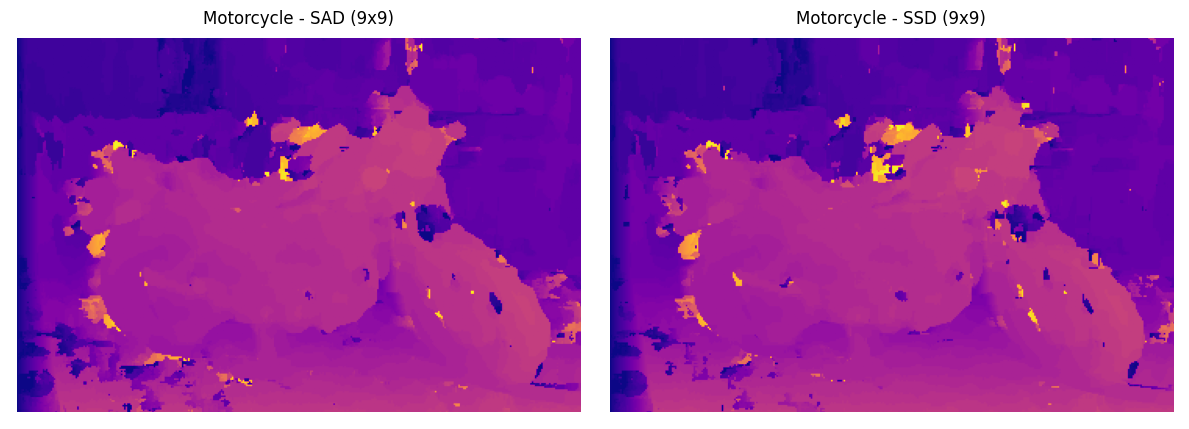

In [25]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, method in zip(axes, ["SAD", "SSD"]):
    ax.imshow(
        maps_motor[(method, 9)],
        cmap="plasma",
        vmin=0,
        vmax=64
    )
    ax.set_title(f"Motorcycle - {method} (9x9)")
    ax.axis("off")

plt.tight_layout()
plt.show()



### Experiment 3: Results — SAD vs SSD on Motorcycle

**Dataset:** Middlebury Stereo Dataset – Motorcycle

**Ground-truth disparity range:** 4.63–31.40 pixels (resized images)

| Window Size | SAD MAE | SSD MAE |
|---|---:|---:|
| 5×5 | 2.897 | 2.916 |
| 9×9 | 2.012 | 2.130 |
| 15×15 | 1.805 | 2.022 |

**Observations:**
- SAD produced slightly lower errors than SSD for all three window sizes.
- Increasing the window size reduced MAE for both methods.
- SAD with a 15×15 window achieved the lowest MAE (1.805 pixels).
- The disparity maps show similar overall scene structures, with some differences around object details and boundaries.

**Comparison with Adirondack:**
- SSD performed better on Adirondack.
- SAD performed better on Motorcycle.
- The 15×15 window produced the lowest MAE in both scenes.

**Conclusion:**
The better matching-cost function depends on the scene. SSD was more accurate on Adirondack, while SAD performed better on Motorcycle. Larger windows improved overall MAE in these experiments, but they may reduce accuracy around object boundaries.

**Limitation:**
These are preliminary results based on two scenes. More testing is needed before selecting the best configuration.
